# Introduction
Welcome to Lab 2, in this lab we will take our first steps into applying ML to satellite data, using landcover analysis as our primary goal.

As covered in Lecture 2, landcover classification is the quintessential remote sensing task in the civil sector. The LandSat programme was originally developed in large part to enable the USA to monitor landcover more easily for a range of agricultral, govermental and finacial problemsets. It remains a primary task for governments and companies around the world.

This is a pixel-wise ML task. We will apply two methods, both of which are available in GEE as ready-to-go algorithms. In this instance we are happy to go with built-in as it allows us to become familiar with an end-to-end GEE ML workflow without getting bogged down in technical detail. No need to re-invent the wheel unless you are going to the [moon](https://www.nasa.gov/feature/ames/artemis-moon-rover-s-wheels-are-ready-to-roll/).

Remember that this is a set of exercises and tutorials that escalate in difficulty. Always show your working and do not neccesarily expect to get full marks on everything.

Use the resources available to you outside of this material. I expect you to search for concepts or terms you do not understand and to look at the documentation of the code packages that we are using in the first instance of getting stuck.
_______________________________________________________________________________

# Set up

In [ ]:
# Install libs if needed, note the --quiet option means a lot less annoying info than as Lab 1 when we did the same!
!pip install geemap --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 42.9 MB/s eta 0:00:00


In [ ]:
# Set up GEE API
import ee
ee.Authenticate()
ee.Initialize(project='brob-503906') #<- Remember to change this to your own project's name!

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [ ]:
# Import other libs
import geemap
import geopandas as gpd
import pandas as pd

# Define Area of Interest (AOI)

In [ ]:
# Define area of interest (e.g., Wellington, NZ)
aoi = ee.Geometry.Rectangle([174.6, -41.4, 174.9, -41.2])
Map = geemap.Map(center=[-41.3, 174.75], zoom=10)
Map.addLayer(aoi, {}, 'AOI')

# Load and Cloud Mask Imagery from Earth Engine

In [ ]:
# Set up your filter Sentinel-2 imagery
# A function that masks clouds in your S2 images via QA band
def mask_s2_clouds(image):
    qa = image.select('QA60')
    cloudBitMask = 1 << 10
    cirrusBitMask = 1 << 11
    mask = qa.bitwiseAnd(cloudBitMask).eq(0).And(
           qa.bitwiseAnd(cirrusBitMask).eq(0))
    return image.updateMask(mask).divide(10000).select(['B2', 'B3', 'B4', 'B8'])

# Now build the clean collection with selected bands
s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterBounds(aoi)
      .filterDate('2021-01-01', '2021-12-31')
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
      .map(mask_s2_clouds)
      .median() #<- think about this step and what it is doing to your image when you build your single composite from the image collection
      .clip(aoi))

(1) What other mathematical [compositing](https://developers.google.com/earth-engine/guides/ic_composite_mosaic) approaches could you take when building your single image from the filtered image collection you create in the cell above? Hint: you currently are doing a 'median-composite'. (3 pts)

In [ ]:
# Set up the visualisation and then once again check it has worked, stacking layers in a sensible order
Map = geemap.Map(center=[-41.3, 174.75], zoom=11) #<- reset the map object to clear out other layers from earlier cells
Map.add_basemap("OpenTopoMap")
Map.addLayer(s2, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 0.3}, 'S2 RGB')
Map.addLayer(aoi, {'color': 'red'}, 'AOI')
Map

Map(center=[-41.3, 174.75], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright…

________________________________________________________________________________

# Training data

We are going to train our data using the European Space Agency (ESA) world landcover map. Given that this is derived from satellite data our logic is at risk of becoming a little circular here. But as a training exercise it is a good way to have easy to access training data of the right size and type to apply to our image.

There are a wide range of landcover datasets in the GEE catalogue that you can use for this purpose:
*   https://developers.google.com/earth-engine/datasets/tags/landuse-landcover

First, we will load in the landcover map we will use to create our training dataset (https://developers.google.com/earth-engine/datasets/catalog/ESA_WorldCover_v100):



Next we need to use our landcover map to [sample](https://developers.google.com/earth-engine/apidocs/ee-image-sample) the Sentinel 2 image, associating each pixel of a given landcover with the spectral band values 'beneath' it.

In [ ]:
# Define valid WorldCover classes (10 to 100, spaced by 10)
valid_classes = ee.List.sequence(10, 100, 10)

# Need to change this to sequential list to avoid the algs thiniing there are 99 classes rather than 9
remap_to = ee.List.sequence(1, 10)

# Load landcover map
landcover = ee.Image('ESA/WorldCover/v100/2020').select('Map').clip(aoi)

# Remap labels: create a new band with remapped values (10 → 1, ..., 100 → 10)
landcover_remapped = landcover.remap(valid_classes, remap_to).rename('Map_remapped')

(2) What year of data was this landcover map (accessed in the cell above) created on? (1 pt)

In [ ]:
# Add landcover original and remapped as bands to Sentinel-2 image
training_data = s2.addBands(landcover_remapped).addBands(landcover_remapped)

Let's inspect the resulting training dataset and make sure that you understand what you have built here.

We are going to:
- Print the first few rows (client-side).
- Check the number of samples per class (server-side with reduceColumns).

This may take a little time to run as we request data both client and server side.

In [ ]:
# Sample the image
bands = ['B2', 'B3', 'B4', 'B8']
sample = training_data.select(bands + ['Map_remapped']).sample(
    region=aoi,
    scale=10,
    numPixels=5000,
    seed=2,
    geometries=True)

# Print first 10 sample points (client-side)
first_10 = sample.limit(10).getInfo()

print('\nFirst 10 training samples:')
for i, feature in enumerate(first_10['features']):
    props = feature['properties']
    print(f"Sample {i+1}: Class={props['Map_remapped']}, B2={props['B2']}, B3={props['B3']}, B4={props['B4']}, B8={props['B8']}")

# Count number of samples per class (server-side)
class_counts = sample.reduceColumns(
    reducer=ee.Reducer.frequencyHistogram(),
    selectors=['Map_remapped'])

print('\nClass distribution in sample:')
print(class_counts.getInfo())



First 10 training samples:
Sample 1: Class=8, B2=0.026200000196695328, B3=0.026599999517202377, B4=0.006200000178068876, B8=0.002899999963119626
Sample 2: Class=8, B2=0.039400000125169754, B3=0.028750000521540642, B4=0.007699999958276749, B8=0.005200000014156103
Sample 3: Class=1, B2=0.01501999981701374, B3=0.03824999928474426, B4=0.022940000519156456, B8=0.2362000048160553
Sample 4: Class=8, B2=0.04690000042319298, B3=0.03150000050663948, B4=0.007675000000745058, B8=0.00430000014603138
Sample 5: Class=1, B2=0.010718749836087227, B3=0.022563636302947998, B4=0.016824999824166298, B8=0.2728666663169861
Sample 6: Class=5, B2=0.1014999970793724, B3=0.09380000084638596, B4=0.09399999678134918, B8=0.12139999866485596
Sample 7: Class=1, B2=0.02449999935925007, B3=0.04910000041127205, B4=0.037300001829862595, B8=0.31119999289512634
Sample 8: Class=8, B2=0.04417499899864197, B3=0.03229999914765358, B4=0.00793750025331974, B8=0.004399999976158142
Sample 9: Class=8, B2=0.03579999879002571, B3=0.

(3) What type of landcover is being sampled in sample number 2 of the dataset? Make sure your random seed is set to 2 in the sampling code so that you get the same answer as me. (1 pt)

We are now ready to start machine learning on classifying the landcover of Wellington!
________________________________________________________________________________

# Random Forest Classification for Landcover
Let us do machine learning properly and first apply a 70/20/10 split that allows us to produce some accuracy statistics.

In [ ]:
# Add random column
sample = sample.randomColumn('random')

# Split
train = sample.filter(ee.Filter.lt('random', 0.7))
valid = sample.filter(ee.Filter.And(ee.Filter.gte('random', 0.7), ee.Filter.lt('random', 0.9)))
test = sample.filter(ee.Filter.gte('random', 0.9))

Our next task is to set up a classifier object, followed by applying it to the image using the .classify operator. This operator hides a LOT of behind the scenes plumbing from Google.

We use the [GEE Random Forest](https://developers.google.com/earth-engine/apidocs/ee-classifier-smilerandomforest) model that they have pre-built for us. Specifying the number of trees to use is the only variable we must set. Othe variables are available, read the docs!

In [ ]:
# Train the RF model
classifier = ee.Classifier.smileRandomForest(numberOfTrees=100).train(
    features=train,
    classProperty='Map_remapped',
    inputProperties=bands)

With the model trained, we just apply it simply using the '.classify' operator.

In [ ]:
# Classify image
classified = s2.select(bands).classify(classifier)

Let's visualize what we have just made!

In [ ]:
# Classified image viz, fresh set up again to make sure we have exactly what we want displayed.
Map = geemap.Map()
Map.add_basemap('TERRAIN')
Map.centerObject(aoi, 10)
#same colours to make it easier to differentiate the maps
esa_palette = ['006400', 'ffbb22', 'ffff4c', 'f096ff', 'fa0000', 'b4b4b4', 'f0f0f0', '0064c8', '0096a0', '00cf75', 'fae6a0']
vis_params = {'min': 1, 'max': 10, 'palette': esa_palette}
Map.addLayer(classified, vis_params, 'Classified')
Map.addLayer(landcover_remapped, vis_params, 'ESA Landcover')
Map

Map(center=[-41.300046246343555, 174.75000000000097], controls=(WidgetControl(options=['position', 'transparen…

(4) Look at the ESA landcover map and our resulting random forest classified Sentinel 2 image map. How are they different and what might be some causes of this difference? (5 pts)

Finally, we will apply our test data split and produce the [summary statistics](https://developers.google.com/machine-learning/crash-course/classification/accuracy-precision-recall) that we need to make smart choices about our training approach.

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd


# Validate
validated = valid.classify(classifier, 'predicted')

# Function to export data for confusion matrix
def fc_to_lists(fc, classProp, predProp):
    values = fc.aggregate_array(classProp).getInfo()
    preds = fc.aggregate_array(predProp).getInfo()
    return values, preds

# Get predicted vs actual from validation set
y_true, y_pred = fc_to_lists(validated, 'Map_remapped', 'predicted')

# Labels for original classes
label_map = {i + 1: valid_classes.get(i).getInfo() for i in range(10)}
label_names = [label_map[i + 1] for i in range(10)]

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(1, 11)))
report = classification_report(y_true, y_pred, labels=list(range(1, 11)), target_names=[str(l) for l in label_names])

# Pretty-print
print("Confusion Matrix:")
print(pd.DataFrame(cm, index=[f"Actual {l}" for l in label_names],
                       columns=[f"Pred {l}" for l in label_names]))
print("\nClassification Report:")
print(report)

Confusion Matrix:
            Pred 10  Pred 20  Pred 30  Pred 40  Pred 50  Pred 60  Pred 70  \
Actual 10       236        0       25        0        3        0        0   
Actual 20         1        0        0        0        0        0        0   
Actual 30        36        0      156        0        5        0        0   
Actual 40         0        0        0        0        0        0        0   
Actual 50         4        0        6        0       22        1        0   
Actual 60         0        0        1        0        2        1        0   
Actual 70         0        0        0        0        0        0        0   
Actual 80         0        0        0        0        6        0        0   
Actual 90         0        0        3        0        0        0        0   
Actual 100        0        0        0        0        0        0        0   

            Pred 80  Pred 90  Pred 100  
Actual 10         0        0         0  
Actual 20         0        0         0  
Actual 30  

In [ ]:
from sklearn.metrics import accuracy_score

# classify the TEST set specifically (not valid) — this is the honest, held-out accuracy check
tested = test.classify(classifier, 'predicted')
y_true_test, y_pred_test = fc_to_lists(tested, 'Map_remapped', 'predicted')

test_accuracy = accuracy_score(y_true_test, y_pred_test)
print(f"2020 RF Test Accuracy: {test_accuracy:.2%}")

2020 RF Test Accuracy: 90.82%


In [ ]:
def classify_year(year):
    s2_year = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
               .filterBounds(aoi)
               .filterDate(f'{year}-01-01', f'{year}-12-31')
               .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
               .map(mask_s2_clouds)
               .median()
               .clip(aoi))

    classified_year = s2_year.select(bands).classify(classifier)
    return classified_year

In [ ]:
# run for three years
years = [2018, 2022, 2024]
classified_by_year = {year: classify_year(year) for year in years}

In [ ]:
# to get scale for figure later
import math

def get_aoi_width_m(aoi):
    """Calculate the real-world width of a rectangular AOI in meters, at its mid-latitude."""
    coords = aoi.bounds().coordinates().getInfo()[0]
    lons = [pt[0] for pt in coords]
    lats = [pt[1] for pt in coords]
    xmin, xmax = min(lons), max(lons)
    ymin, ymax = min(lats), max(lats)
    lat_mid = (ymin + ymax) / 2
    m_per_degree_lon = 111320 * math.cos(math.radians(lat_mid))  #<- meters per degree longitude, adjusted for latitude
    width_m = (xmax - xmin) * m_per_degree_lon
    return width_m

aoi_width_m = get_aoi_width_m(aoi)
thumbnail_px = 600   #<- matches your 'dimensions': 600 setting

dx_meters_per_pixel = aoi_width_m / thumbnail_px
print(f"Each pixel represents approximately {dx_meters_per_pixel:.1f} meters")

Each pixel represents approximately 41.8 meters


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.4/86.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 69.6 MB/s eta 0:00:00


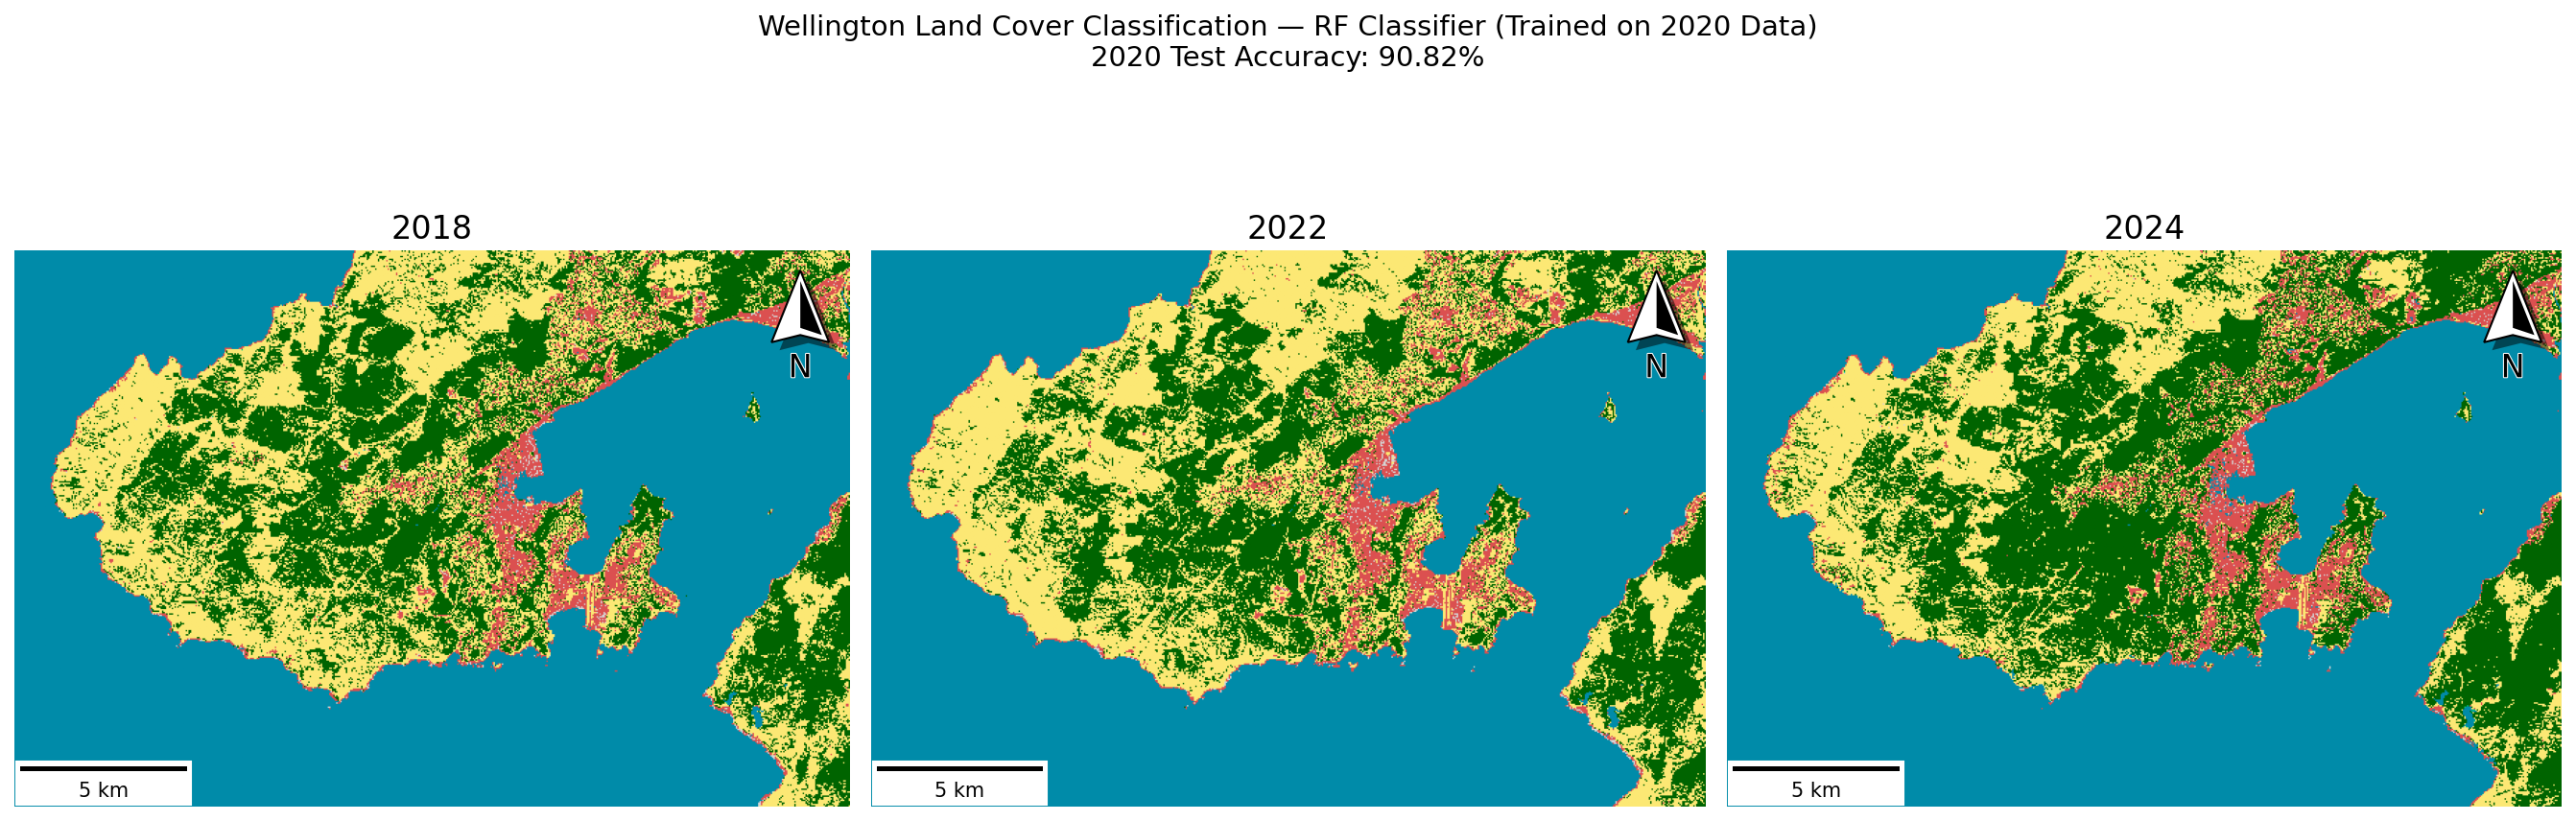

In [ ]:
# build the figure
!pip install matplotlib-scalebar matplotlib-map-utils geopandas --quiet

import matplotlib.pyplot as plt
import urllib.request, tempfile
import matplotlib.image as mpimg
import geopandas as gpd
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib_map_utils import north_arrow

fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=150)

for ax, year in zip(axes, years):
    thumb_url = classified_by_year[year].getThumbURL({
        'dimensions': 600,
        'region': aoi,
        'format': 'png',
        'min': 1, 'max': 10,
        'palette': esa_palette   #<- reusing your existing palette from the visualization cell
    })
    with tempfile.NamedTemporaryFile(suffix=".png") as f:
        urllib.request.urlretrieve(thumb_url, f.name)
        img = mpimg.imread(f.name)
        ax.imshow(img)
        ax.set_title(f"{year}", fontsize=16)
        ax.axis('off')
# scale os 1 pixel = 41.8m so dx = 41.8
        scalebar = ScaleBar(dx=41.8, units="m", location="lower left", frameon=True)
        ax.add_artist(scalebar)
        north_arrow(ax=ax, location="upper right", scale=0.5, rotation={"degrees": 0})


fig.suptitle(f"Wellington Land Cover Classification — RF Classifier (Trained on 2020 Data)\n"
             f"2020 Test Accuracy: {test_accuracy:.2%}",
             fontsize=14, y=1.05)

plt.tight_layout()
plt.savefig('wellington_multi_year.png', dpi=300, bbox_inches='tight')
plt.show()

(5) Exercise: modify the code so that you feed into your random forest classifier that has been trained on 2020 data, on other years of Sentinel 2 data than 2020. Produce a publication quality figure that presents the following:
*   Landcover maps of Wellington for 2018, 2022 and 2024
*   The Test accuracy averages of the RF classifier for 2020.
*   Include a sentence in your figure caption that explains why you cannot state the accuracy of the classifier for years other than 2020.

(15 pts)
_______________________________________________________________________________


# SVMs Applied to Satellite Data

In [ ]:
# Define and train the SVM classifier
class_property = 'Map_remapped'
svm = ee.Classifier.libsvm(kernelType='RBF', gamma=0.5, cost=10).train(
    features=train,
    classProperty=class_property,
    inputProperties=bands
)

# Classify validation and test sets
val_classified = valid.classify(svm)
test_classified = test.classify(svm)

# Evaluate test performance
test_matrix = test_classified.errorMatrix(class_property, 'classification')
print("Confusion Matrix:")
print(pd.DataFrame(cm, index=[f"Actual {l}" for l in label_names],
                       columns=[f"Pred {l}" for l in label_names]))
print("\nClassification Report:")
print(report)

Confusion Matrix:
            Pred 10  Pred 20  Pred 30  Pred 40  Pred 50  Pred 60  Pred 70  \
Actual 10       236        0       25        0        3        0        0   
Actual 20         1        0        0        0        0        0        0   
Actual 30        36        0      156        0        5        0        0   
Actual 40         0        0        0        0        0        0        0   
Actual 50         4        0        6        0       22        1        0   
Actual 60         0        0        1        0        2        1        0   
Actual 70         0        0        0        0        0        0        0   
Actual 80         0        0        0        0        6        0        0   
Actual 90         0        0        3        0        0        0        0   
Actual 100        0        0        0        0        0        0        0   

            Pred 80  Pred 90  Pred 100  
Actual 10         0        0         0  
Actual 20         0        0         0  
Actual 30  

(6) Exercise: train an SVM model using the Landcare NZ 2018 landcover database record for the region. Producing a landcover map of Great Barrier (Aotea) Island for 2018 (based off the Austral summer of 18/19 S2).

Your map should be presented at a publication quality level with all the usual map components (scale, legend, north arrow, data attribution).

You will need to provide performance statistics of the model within your figure.

*   Here you can access the landcover database: https://lris.scinfo.org.nz/layer/104400-lcdb-v50-land-cover-database-version-50-mainland-new-zealand/. You will need to explore for yourself how to extract this data and then upload it to colab, then how to plug it into the SVM algorithim. I have provided some starter code below.

An intial workflow to get the data into the state you need it in to then use it as training data might look like:
- Download the ZIP manually from their browser, having set your area of interest and used the 'Export' tool top right.
- Upload it to Colab.
- Unzip it and load with GeoPandas.
(25 pts)



In [ ]:
# Code to get you started
import zipfile
import geopandas as gpd

# Upload the ZIP manually using the Colab UI
from google.colab import files
uploaded = files.upload()  # <- Expects a ZIP

Saving lris-lcdb-v50-land-cover-database-version-50-mainland-new-zealand-SHP.zip to lris-lcdb-v50-land-cover-database-version-50-mainland-new-zealand-SHP.zip


In [ ]:
# rest of the code so their is no need to load the ZIP again
# Unzip
with zipfile.ZipFile("lris-lcdb-v50-land-cover-database-version-50-mainland-new-zealand-SHP.zip", 'r') as zip_ref: #<- Check file names
    zip_ref.extractall("lcdb")

# Read shapefile
gdf = gpd.read_file("lcdb/lcdb-v50-land-cover-database-version-50-mainland-new-zealand.shp") #<- Check file names
print(gdf.head())

           Name_2018          Name_2012          Name_2008          Name_2001  \
0  Indigenous Forest  Indigenous Forest  Indigenous Forest  Indigenous Forest   
1     Sand or Gravel     Sand or Gravel     Sand or Gravel     Sand or Gravel   
2  Indigenous Forest  Indigenous Forest  Indigenous Forest  Indigenous Forest   
3     Sand or Gravel     Sand or Gravel     Sand or Gravel     Sand or Gravel   
4  Indigenous Forest  Indigenous Forest  Indigenous Forest  Indigenous Forest   

           Name_1996  Class_2018  Class_2012  Class_2008  Class_2001  \
0  Indigenous Forest          69          69          69          69   
1     Sand or Gravel          10          10          10          10   
2  Indigenous Forest          69          69          69          69   
3     Sand or Gravel          10          10          10          10   
4  Indigenous Forest          69          69          69          69   

   Class_1996  ... Wetland_96 Onshore_18 Onshore_12 Onshore_08 Onshore_01  \
0  

In [ ]:
print(gdf.crs)

EPSG:2193


In [ ]:
gdf_wgs84 = gdf.to_crs(epsg=4326)
print(gdf_wgs84.geometry.iloc[0])

POLYGON ((175.444421232187 -36.10971159324183, 175.4443868879611 -36.109738915900444, 175.4443843936041 -36.109740900163494, 175.44436390324572 -36.10975720070871, 175.44406629025357 -36.1098517454069, 175.4437511967719 -36.109965906557505, 175.44319147536748 -36.11011199291277, 175.44292014723774 -36.1101390741526, 175.4427337649464 -36.11033679047112, 175.44251980980286 -36.11028729095918, 175.4424313242203 -36.11020202606244, 175.44238295794827 -36.110155419928795, 175.44236318776134 -36.109945748515884, 175.44236898999347 -36.109905611305834, 175.4424014528541 -36.10968102919998, 175.44253229903134 -36.109619108833265, 175.44272173578818 -36.10968493041444, 175.44287609748304 -36.10957439015003, 175.44283245506165 -36.1094155259553, 175.4433650960672 -36.10931917837206, 175.44336556771808 -36.109319093036426, 175.44361981503835 -36.109093507182244, 175.44374378311574 -36.10905450418274, 175.443864275752 -36.10907198504927, 175.44434700548163 -36.10936389814009, 175.4444104682502 -3

In [ ]:
import shapely.geometry

gbi_bbox = shapely.geometry.box(175.35, -36.35, 175.55, -36.10)  # adjust if your drawn export area differed
gdf_gbi = gdf_wgs84[gdf_wgs84.geometry.intersects(gbi_bbox)]
print(f"Number of polygons covering Great Barrier Island: {len(gdf_gbi)}")

Number of polygons covering Great Barrier Island: 410


In [ ]:
gdf_gbi_clean = gdf_gbi[['Class_2018', 'Name_2018', 'geometry']]

import json
geojson_dict = json.loads(gdf_gbi_clean.to_json())
lcdb_fc = ee.FeatureCollection(geojson_dict)

bounds = gdf_gbi.total_bounds
buffer = 0.02
aoi_gbi = ee.Geometry.Rectangle([
    bounds[0] - buffer, bounds[1] - buffer,
    bounds[2] + buffer, bounds[3] + buffer
])

s2_gbi = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(aoi_gbi)
          .filterDate('2018-12-01', '2019-02-28')
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
          .map(mask_s2_clouds)
          .median()
          .clip(aoi_gbi))

# rasterise
lcdb_image = lcdb_fc.filter(ee.Filter.notNull(['Class_2018'])).reduceToImage(
    properties=['Class_2018'],
    reducer=ee.Reducer.first()
).rename('lcdb_class').clip(aoi_gbi)

# sample points
training_data_gbi = s2_gbi.addBands(lcdb_image)

sample_gbi = training_data_gbi.select(bands + ['lcdb_class']).sample(
    region=aoi_gbi,
    scale=10,
    numPixels=5000,
    seed=2,
    geometries=True
)

In [ ]:
# train
sample_gbi = sample_gbi.randomColumn('random')
train_gbi = sample_gbi.filter(ee.Filter.lt('random', 0.8))
test_gbi = sample_gbi.filter(ee.Filter.gte('random', 0.8))

svm_gbi = ee.Classifier.libsvm(kernelType='RBF', gamma=0.5, cost=10).train(
    features=train_gbi,
    classProperty='lcdb_class',
    inputProperties=bands
)

# classify & accuracy
classified_gbi = s2_gbi.select(bands).classify(svm_gbi)

from sklearn.metrics import accuracy_score

tested_gbi = test_gbi.classify(svm_gbi, 'predicted')
y_true_gbi, y_pred_gbi = fc_to_lists(tested_gbi, 'lcdb_class', 'predicted')

svm_accuracy = accuracy_score(y_true_gbi, y_pred_gbi)
print(f"SVM Test Accuracy: {svm_accuracy:.2%}")

SVM Test Accuracy: 52.22%


In [ ]:
# check how much each class matters
class_sizes = gdf_gbi_clean.groupby(['Class_2018', 'Name_2018']).size().reset_index(name='polygon_count')
class_sizes = class_sizes.sort_values('polygon_count', ascending=False)
print(class_sizes)

    Class_2018                                  Name_2018  polygon_count
18          69                          Indigenous Forest             88
16          54           Broadleaved Indigenous Hardwoods             58
15          52                       Manuka and/or Kanuka             58
3           10                             Sand or Gravel             57
10          40            High Producing Exotic Grassland             47
20          71                              Exotic Forest             21
11          41                    Low Producing Grassland             20
13          46               Herbaceous Saline Vegetation             14
0            1                 Built-up Area (settlement)             10
19          70                                   Mangrove              8
14          51                         Gorse and/or Broom              6
12          45           Herbaceous Freshwater Vegetation              5
9           33  Orchard, Vineyard or Other Perennia

In [ ]:
# colour generation
import matplotlib.cm as cm
import matplotlib.colors as mcolors

class_codes = sorted(gdf_gbi_clean['Class_2018'].unique())

cmap = cm.get_cmap('tab20', len(class_codes))
class_colors = {code: mcolors.to_hex(cmap(i)) for i, code in enumerate(class_codes)}

print(class_colors)

{np.int32(1): '#1f77b4', np.int32(2): '#aec7e8', np.int32(6): '#ff7f0e', np.int32(10): '#ffbb78', np.int32(12): '#2ca02c', np.int32(16): '#98df8a', np.int32(20): '#d62728', np.int32(21): '#ff9896', np.int32(22): '#9467bd', np.int32(33): '#c5b0d5', np.int32(40): '#8c564b', np.int32(41): '#c49c94', np.int32(45): '#e377c2', np.int32(46): '#f7b6d2', np.int32(51): '#7f7f7f', np.int32(52): '#c7c7c7', np.int32(54): '#bcbd22', np.int32(64): '#dbdb8d', np.int32(69): '#17becf', np.int32(70): '#9edae5', np.int32(71): '#9edae5'}


In [ ]:
# classes to group into "Other" — adjust this threshold if you want a different cutoff
threshold = 5
major_classes = class_sizes[class_sizes['polygon_count'] >= threshold]['Class_2018'].tolist()

# create a new column: either the real class, or a special "Other" code (use 999, unused by LCDB)
gdf_gbi_clean = gdf_gbi_clean.copy()
gdf_gbi_clean['Class_2018_grouped'] = gdf_gbi_clean['Class_2018'].apply(
    lambda x: x if x in major_classes else 999
)

# matching label column, for the legend
name_lookup = dict(zip(gdf_gbi_clean['Class_2018'], gdf_gbi_clean['Name_2018']))
gdf_gbi_clean['Name_2018_grouped'] = gdf_gbi_clean['Class_2018_grouped'].apply(
    lambda x: name_lookup.get(x, 'Other') if x != 999 else 'Other'
)

print(gdf_gbi_clean['Name_2018_grouped'].value_counts())

Name_2018_grouped
Indigenous Forest                   88
Manuka and/or Kanuka                58
Broadleaved Indigenous Hardwoods    58
Sand or Gravel                      57
High Producing Exotic Grassland     47
Exotic Forest                       21
Low Producing Grassland             20
Other                               18
Herbaceous Saline Vegetation        14
Built-up Area (settlement)          10
Mangrove                             8
Gorse and/or Broom                   6
Herbaceous Freshwater Vegetation     5
Name: count, dtype: int64


Re-training the new data:

In [ ]:
# FeatureCollection using the grouped column
geojson_dict = json.loads(gdf_gbi_clean[['Class_2018_grouped', 'Name_2018_grouped', 'geometry']].to_json())
lcdb_fc = ee.FeatureCollection(geojson_dict)

# rasterize using the grouped column
lcdb_image = lcdb_fc.filter(ee.Filter.notNull(['Class_2018_grouped'])).reduceToImage(
    properties=['Class_2018_grouped'],
    reducer=ee.Reducer.first()
).rename('lcdb_class').clip(aoi_gbi)

# sample
training_data_gbi = s2_gbi.addBands(lcdb_image)
sample_gbi = training_data_gbi.select(bands + ['lcdb_class']).sample(
    region=aoi_gbi, scale=10, numPixels=5000, seed=2, geometries=True
)
sample_gbi = sample_gbi.randomColumn('random')
train_gbi = sample_gbi.filter(ee.Filter.lt('random', 0.8))
test_gbi = sample_gbi.filter(ee.Filter.gte('random', 0.8))

In [ ]:
# train
svm_gbi = ee.Classifier.libsvm(kernelType='RBF', gamma=0.5, cost=10).train(
    features=train_gbi, classProperty='lcdb_class', inputProperties=bands
)

classified_gbi = s2_gbi.select(bands).classify(svm_gbi)

tested_gbi = test_gbi.classify(svm_gbi, 'predicted')
y_true_gbi, y_pred_gbi = fc_to_lists(tested_gbi, 'lcdb_class', 'predicted')
svm_accuracy = accuracy_score(y_true_gbi, y_pred_gbi)
print(f"SVM Test Accuracy (grouped classes): {svm_accuracy:.2%}")

SVM Test Accuracy (grouped classes): 53.56%


In [ ]:
# generate colors for grouped codes

class_codes_grouped = sorted([int(x) for x in gdf_gbi_clean['Class_2018_grouped'].unique()])

cmap = cm.get_cmap('tab20', len(class_codes_grouped))

# Manually chosen colors, matched to what each land cover actually looks like
class_colors = {
    1: '#808080',    # built-up Area (settlement) — grey,
    10: '#f5deb3',   # sand or gravel — sandy tan
    40: '#d4e157',   # high producing exotic grassland — bright yellow-green
    41: '#aed581',   # low producing grassland — paler green
    45: '#4fc3f7',   # herbaceous freshwater vegetation — light blue-green
    46: '#80cbc4',   # herbaceous saline vegetation — teal
    51: '#c2a14d',   # gorse and/or broom — golden/brown
    52: '#87A88E',   # manuka and/or kanuka — grey green
    54: '#1b5e20',   # broadleaved indigenous hardwoods — deep forest green
    69: '#0d3b0d',   # indigenous forest — darkest green
    70: '#6a4c93',   # mangrove — purplish (distinct from other greens)
    71: '#388e3c',   # exotic forest — medium green
    999: '#ff00ff',  # other — magenta
}

code_to_name = dict(zip(gdf_gbi_clean['Class_2018_grouped'], gdf_gbi_clean['Name_2018_grouped']))

print(class_colors)

# Build a lookup from code -> display name, for the legend text
code_to_name = dict(zip(gdf_gbi_clean['Class_2018_grouped'], gdf_gbi_clean['Name_2018_grouped']))

print(class_colors)

{1: '#808080', 10: '#f5deb3', 40: '#d4e157', 41: '#aed581', 45: '#4fc3f7', 46: '#80cbc4', 51: '#c2a14d', 52: '#87A88E', 54: '#1b5e20', 69: '#0d3b0d', 70: '#6a4c93', 71: '#388e3c', 999: '#ff00ff'}
{1: '#808080', 10: '#f5deb3', 40: '#d4e157', 41: '#aed581', 45: '#4fc3f7', 46: '#80cbc4', 51: '#c2a14d', 52: '#87A88E', 54: '#1b5e20', 69: '#0d3b0d', 70: '#6a4c93', 71: '#388e3c', 999: '#ff00ff'}


In [ ]:
# remap codes to a clean sequence for visualization

remap_from = class_codes_grouped
remap_to_clean = list(range(1, len(class_codes_grouped) + 1))

remap_dict = dict(zip(remap_from, remap_to_clean))
print(remap_dict)  # keep this handy — you'll need it to match legend colors to the classified image

{1: 1, 10: 2, 40: 3, 41: 4, 45: 5, 46: 6, 51: 7, 52: 8, 54: 9, 69: 10, 70: 11, 71: 12, 999: 13}


In [ ]:
# apply remap to classified image

# build EE lists for the remap
ee_from = ee.List(remap_from)
ee_to = ee.List(remap_to_clean)

classified_gbi_remapped = classified_gbi.remap(ee_from, ee_to)

# build palette list in correct order
palette_ordered = [class_colors[code] for code in remap_from]  # order matches remap_to_clean automatically
vis_params_gbi = {'min': 1, 'max': len(remap_to_clean), 'palette': palette_ordered}

print(class_colors)
print(remap_dict)

{1: '#808080', 10: '#f5deb3', 40: '#d4e157', 41: '#aed581', 45: '#4fc3f7', 46: '#80cbc4', 51: '#c2a14d', 52: '#87A88E', 54: '#1b5e20', 69: '#0d3b0d', 70: '#6a4c93', 71: '#388e3c', 999: '#ff00ff'}
{1: 1, 10: 2, 40: 3, 41: 4, 45: 5, 46: 6, 51: 7, 52: 8, 54: 9, 69: 10, 70: 11, 71: 12, 999: 13}


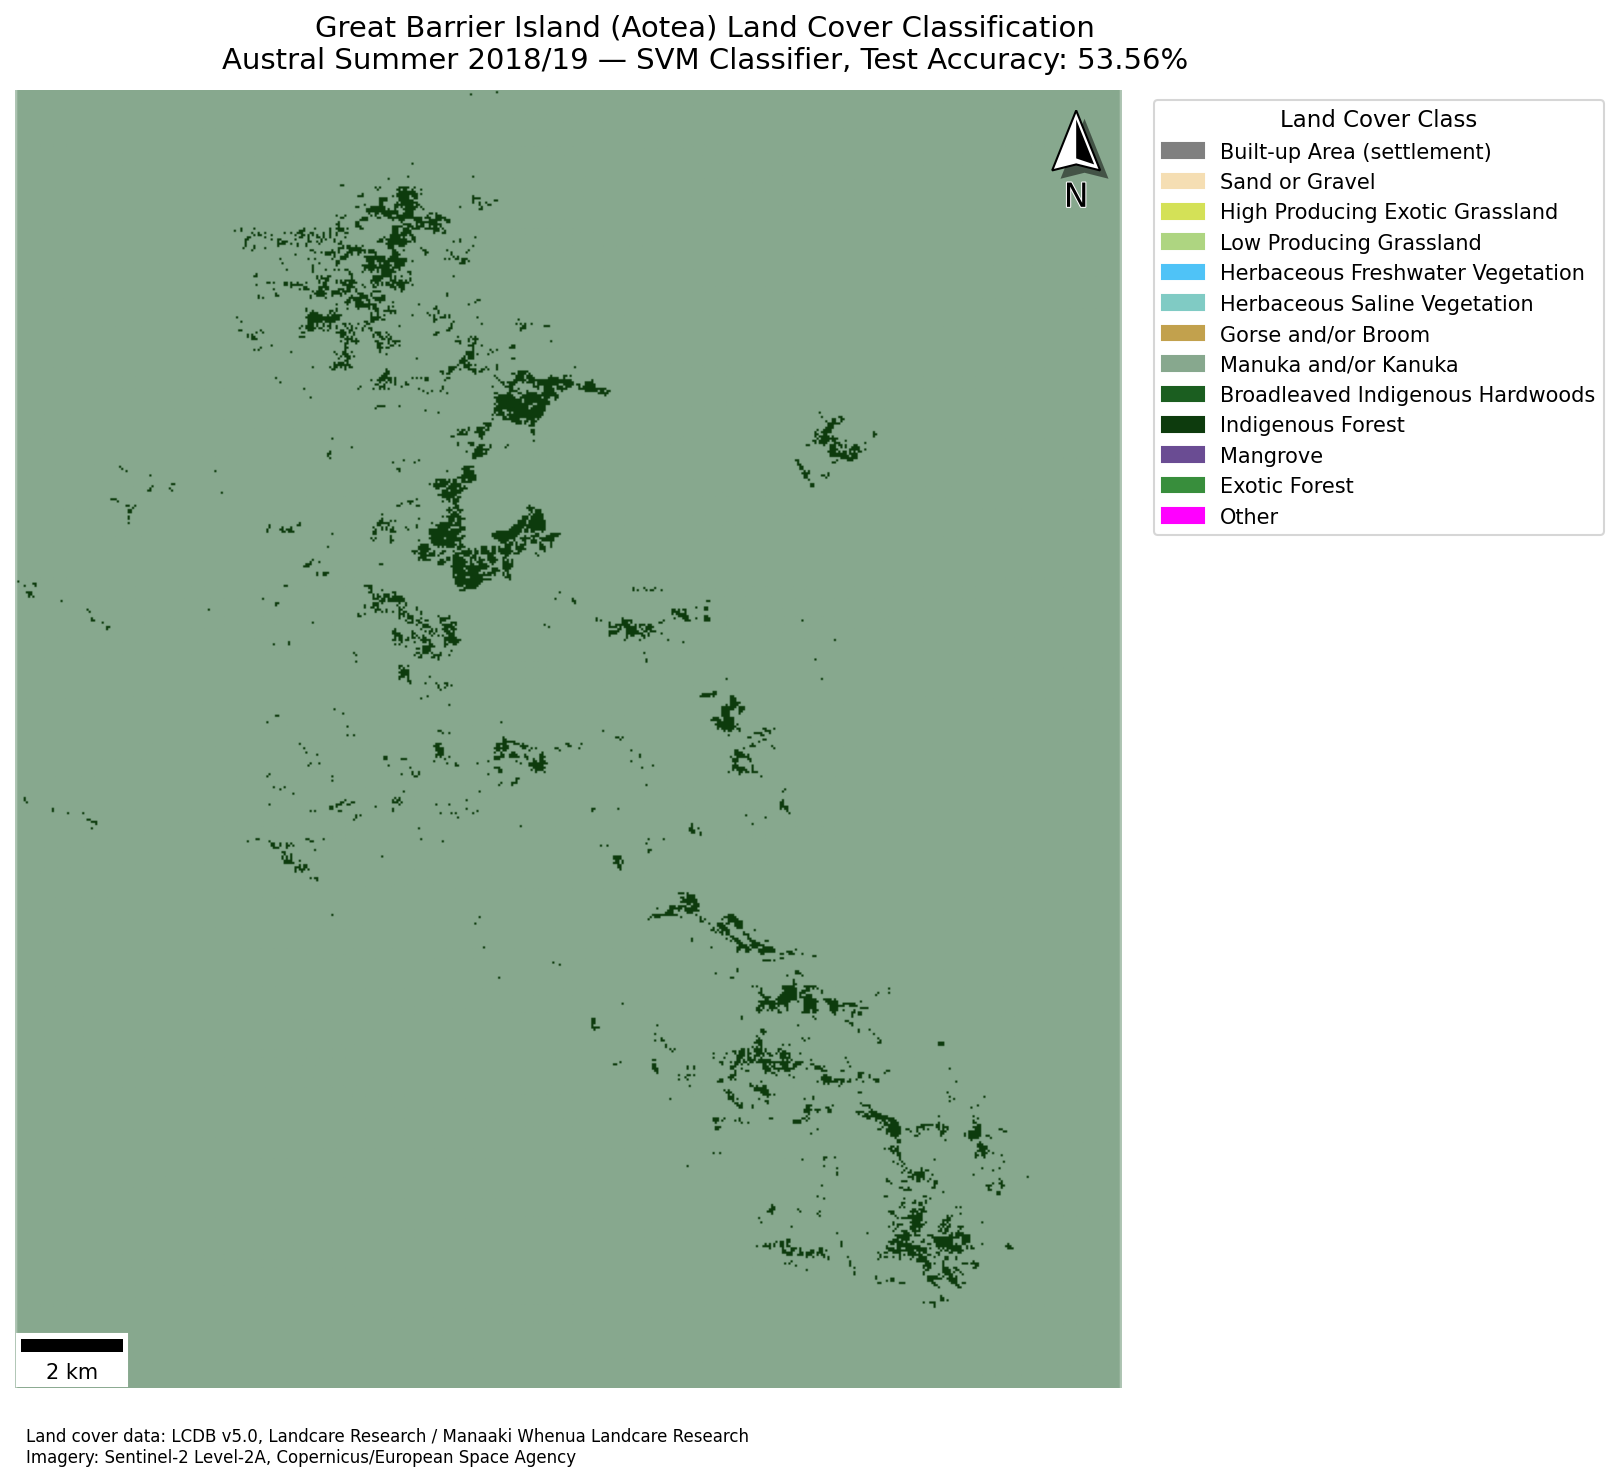

In [ ]:
# build the figure
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import urllib.request, tempfile
import matplotlib.image as mpimg
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib_map_utils import north_arrow
import math

#  get the thumbnail using your remapped classified image
thumbnail_px = 600
thumb_url = classified_gbi_remapped.getThumbURL({
    'dimensions': thumbnail_px,
    'region': aoi_gbi,
    'format': 'png',
    'min': 1,
    'max': 13,
    'palette': palette_ordered
})

fig, ax = plt.subplots(figsize=(12, 10), dpi=150)

with tempfile.NamedTemporaryFile(suffix=".png") as f:
    urllib.request.urlretrieve(thumb_url, f.name)
    img = mpimg.imread(f.name)
    ax.imshow(img)
    ax.axis('off')

# legend: one patch per class, ordered to match remap values 1-13
legend_elements = []
for code in remap_from:  # already sorted, matches palette_ordered order
    label = code_to_name[code]
    color = class_colors[code]
    legend_elements.append(mpatches.Patch(color=color, label=label))

ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1),
          fontsize=10, title="Land Cover Class", title_fontsize=11, frameon=True)

# scale bar
def get_aoi_width_m(aoi):
    coords = aoi.bounds().coordinates().getInfo()[0]
    lons = [pt[0] for pt in coords]
    lats = [pt[1] for pt in coords]
    xmin, xmax = min(lons), max(lons)
    ymin, ymax = min(lats), max(lats)
    lat_mid = (ymin + ymax) / 2
    m_per_degree_lon = 111320 * math.cos(math.radians(lat_mid))
    return (xmax - xmin) * m_per_degree_lon

aoi_width_m = get_aoi_width_m(aoi_gbi)
dx = aoi_width_m / thumbnail_px

scalebar = ScaleBar(dx=dx, units="m", location="lower left", frameon=True)
ax.add_artist(scalebar)

# north arrow
north_arrow(ax=ax, location="upper right", scale=0.4, rotation={"degrees": 0})

# data attribution
ax.text(0.01, -0.03,
        "Land cover data: LCDB v5.0, Landcare Research / Manaaki Whenua Landcare Research\n"
        "Imagery: Sentinel-2 Level-2A, Copernicus/European Space Agency",
        transform=ax.transAxes, fontsize=8, va='top')

# title + performance stats on the figure itself
fig.suptitle(f"Great Barrier Island (Aotea) Land Cover Classification\n"
             f"Austral Summer 2018/19 — SVM Classifier, Test Accuracy: {svm_accuracy:.2%}",
             fontsize=14, y=0.98)

plt.tight_layout()
plt.savefig('gbi_landcover.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
class_histogram = classified_gbi_remapped.reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=aoi_gbi,
    scale=10,
    maxPixels=1e9
).getInfo()

print(class_histogram)

# Shows that the SVM predicted 94.6% of the island as manuka/kanuka showing an ocean misclassification issue

{'remapped': {'10': 308486.03529411764, '8': 11491226.36078434}}


Fix the ocean misclassification problem

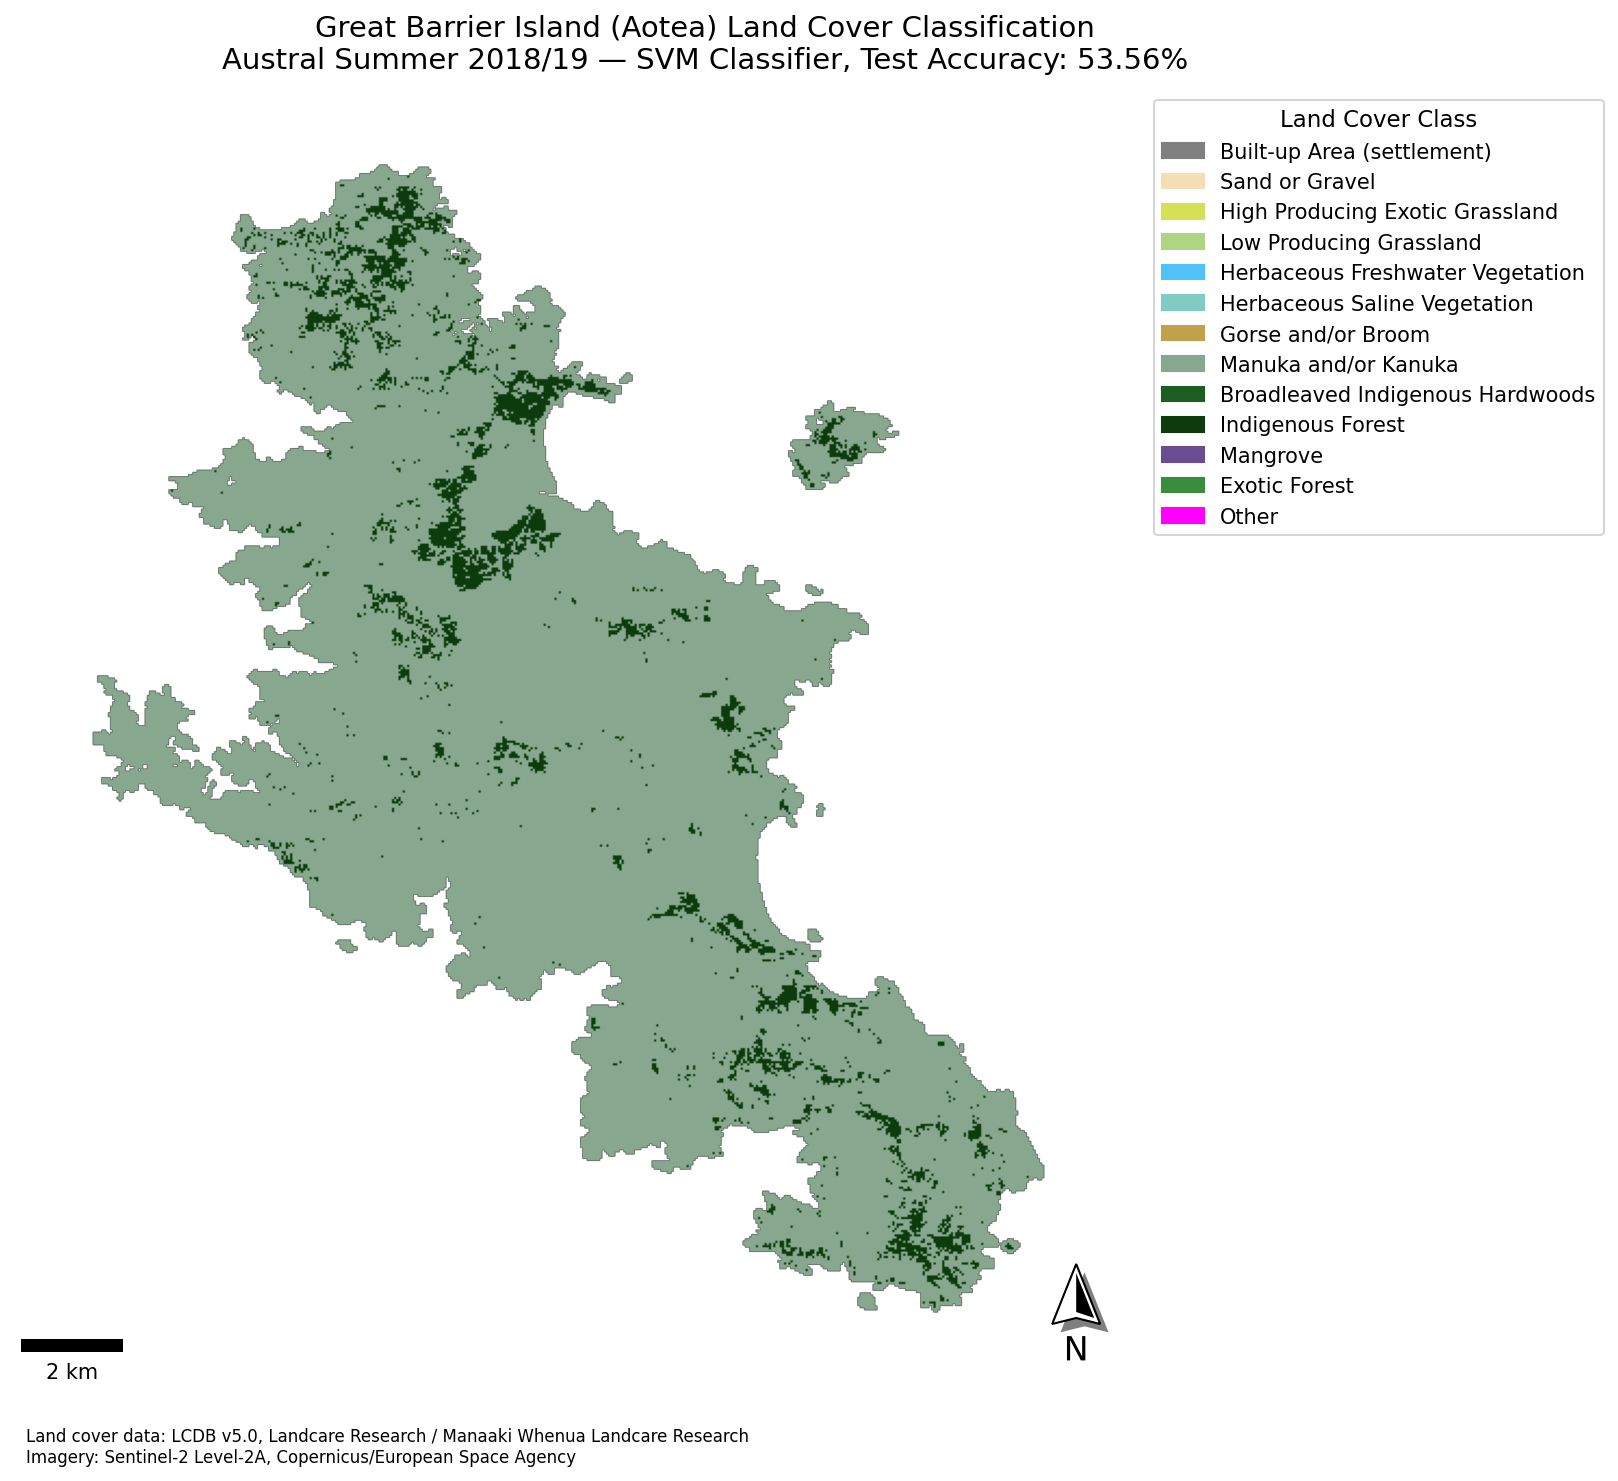

In [ ]:
# build the figure
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import urllib.request, tempfile
import matplotlib.image as mpimg
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib_map_utils import north_arrow
import math

land_mask = lcdb_image.mask()
classified_gbi_remapped = classified_gbi_remapped.updateMask(land_mask)

fig, ax = plt.subplots(figsize=(12, 10), dpi=150)
ax.set_facecolor('#4a90d9')

thumbnail_px = 600
thumb_url = classified_gbi_remapped.getThumbURL({
    'dimensions': thumbnail_px,
    'region': aoi_gbi,
    'format': 'png',
    'min': 1,
    'max': 13,
    'palette': palette_ordered
})


with tempfile.NamedTemporaryFile(suffix=".png") as f:
    urllib.request.urlretrieve(thumb_url, f.name)
    img = mpimg.imread(f.name)
    ax.set_facecolor('#4a90d9')  # a reasonably ocean-like blue, adjust to taste
    ax.imshow(img)
    ax.imshow(img)
    ax.axis('off')

# legend
legend_elements = []
for code in remap_from:  # already sorted, matches palette_ordered order
    label = code_to_name[code]
    color = class_colors[code]
    legend_elements.append(mpatches.Patch(color=color, label=label))

ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1),
          fontsize=10, title="Land Cover Class", title_fontsize=11, frameon=True)

# scale bar
def get_aoi_width_m(aoi):
    coords = aoi.bounds().coordinates().getInfo()[0]
    lons = [pt[0] for pt in coords]
    lats = [pt[1] for pt in coords]
    xmin, xmax = min(lons), max(lons)
    ymin, ymax = min(lats), max(lats)
    lat_mid = (ymin + ymax) / 2
    m_per_degree_lon = 111320 * math.cos(math.radians(lat_mid))
    return (xmax - xmin) * m_per_degree_lon

aoi_width_m = get_aoi_width_m(aoi_gbi)
dx = aoi_width_m / thumbnail_px
scalebar = ScaleBar(dx=dx, units="m", location="lower left", frameon=True)
ax.add_artist(scalebar)

# north arrow
north_arrow(ax=ax, location="lower right", scale=0.4, rotation={"degrees": 0})

# data attribution
ax.text(0.01, -0.03,
        "Land cover data: LCDB v5.0, Landcare Research / Manaaki Whenua Landcare Research\n"
        "Imagery: Sentinel-2 Level-2A, Copernicus/European Space Agency",
        transform=ax.transAxes, fontsize=8, va='top')

# title + performance stats on the figure itself
fig.suptitle(f"Great Barrier Island (Aotea) Land Cover Classification\n"
             f"Austral Summer 2018/19 — SVM Classifier, Test Accuracy: {svm_accuracy:.2%}",
             fontsize=14, y=0.98)

plt.tight_layout()
plt.savefig('gbi_landcover.png', dpi=300, bbox_inches='tight')
plt.show()

Number of ocean pixels detected: 215897


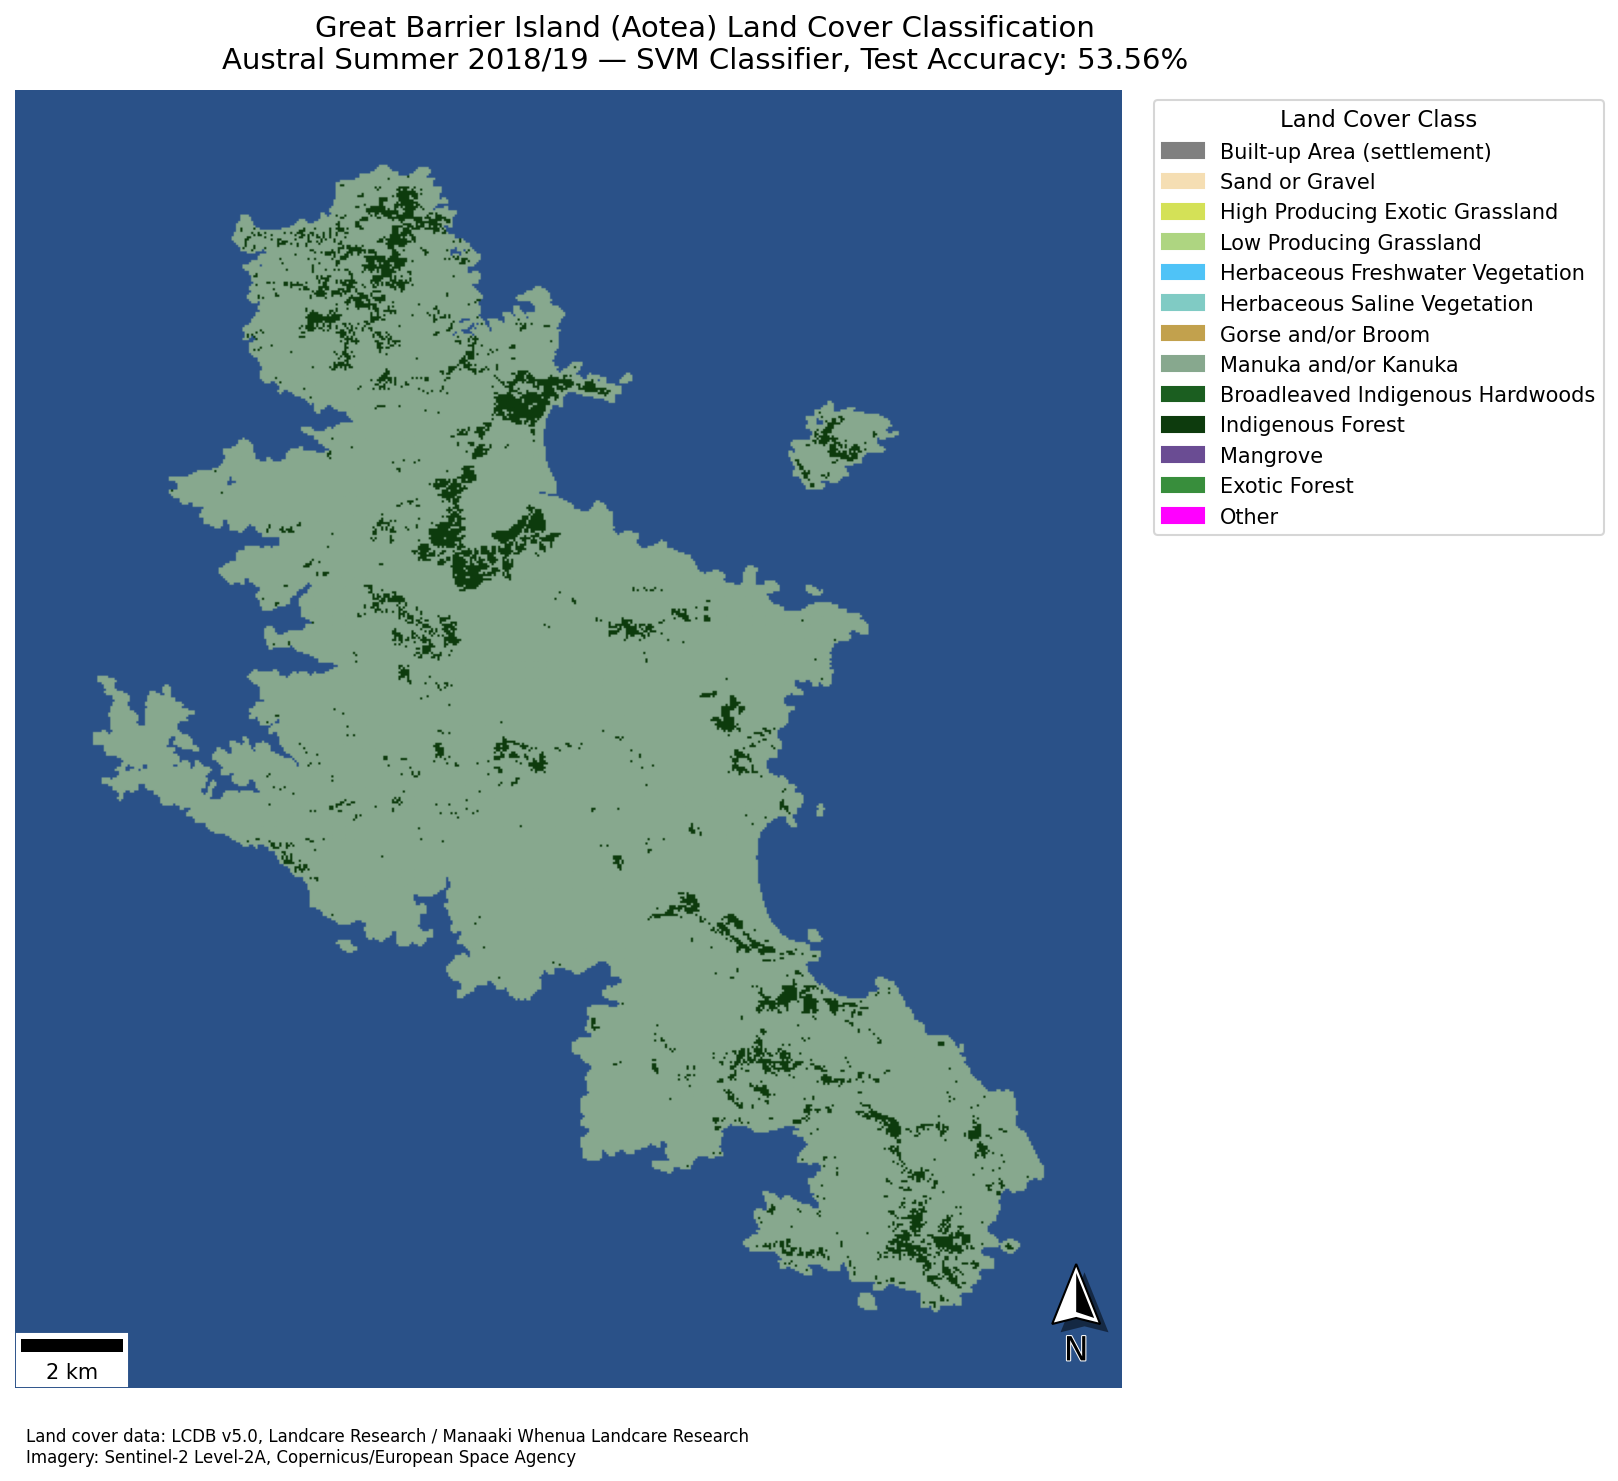

(600, 511, 4)


In [ ]:
# build the figure
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import urllib.request, tempfile
import matplotlib.image as mpimg
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib_map_utils import north_arrow
import math

land_mask = lcdb_image.mask()
classified_gbi_remapped = classified_gbi_remapped.updateMask(land_mask)

fig, ax = plt.subplots(figsize=(12, 10), dpi=150)
ax.set_facecolor('#4a90d9')

thumbnail_px = 600
thumb_url = classified_gbi_remapped.getThumbURL({
    'dimensions': thumbnail_px,
    'region': aoi_gbi,
    'format': 'png',
    'min': 1,
    'max': 13,
    'palette': palette_ordered
})

# legend
legend_elements = []
for code in remap_from:  # already sorted, matches palette_ordered order
    label = code_to_name[code]
    color = class_colors[code]
    legend_elements.append(mpatches.Patch(color=color, label=label))

ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1),
          fontsize=10, title="Land Cover Class", title_fontsize=11, frameon=True)

import numpy as np

with tempfile.NamedTemporaryFile(suffix=".png") as f:
    urllib.request.urlretrieve(thumb_url, f.name)
    img = mpimg.imread(f.name)

    # Masked/no-data pixels have alpha = 0 (fully transparent) — THIS is the real ocean indicator
    is_ocean = img[:, :, 3] == 0
    print("Number of ocean pixels detected:", is_ocean.sum())

    img_colored = img[:, :, :3].copy()
    ocean_blue = np.array([0.167, 0.320, 0.535])
    img_colored[is_ocean] = ocean_blue

    ax.imshow(img_colored)
    ax.axis('off')

# scale bar
def get_aoi_width_m(aoi):
    coords = aoi.bounds().coordinates().getInfo()[0]
    lons = [pt[0] for pt in coords]
    lats = [pt[1] for pt in coords]
    xmin, xmax = min(lons), max(lons)
    ymin, ymax = min(lats), max(lats)
    lat_mid = (ymin + ymax) / 2
    m_per_degree_lon = 111320 * math.cos(math.radians(lat_mid))
    return (xmax - xmin) * m_per_degree_lon

aoi_width_m = get_aoi_width_m(aoi_gbi)
dx = aoi_width_m / thumbnail_px
scalebar = ScaleBar(dx=dx, units="m", location="lower left", frameon=True)
ax.add_artist(scalebar)

# north arrow
north_arrow(ax=ax, location="lower right", scale=0.4, rotation={"degrees": 0})

# data attribution
ax.text(0.01, -0.03,
        "Land cover data: LCDB v5.0, Landcare Research / Manaaki Whenua Landcare Research\n"
        "Imagery: Sentinel-2 Level-2A, Copernicus/European Space Agency",
        transform=ax.transAxes, fontsize=8, va='top')

# title + performance stats on the figure itself
fig.suptitle(f"Great Barrier Island (Aotea) Land Cover Classification\n"
             f"Austral Summer 2018/19 — SVM Classifier, Test Accuracy: {svm_accuracy:.2%}",
             fontsize=14, y=0.98)

plt.tight_layout()
plt.savefig('gbi_landcover.png', dpi=300, bbox_inches='tight')
plt.show()


print(img.shape)

Can we improve the accuracy?

In [ ]:
# Use stratified sampling
sample_gbi = training_data_gbi.stratifiedSample(
    numPoints=100,          # aim for up to 100 points per class
    classBand='lcdb_class',
    region=aoi_gbi,
    scale=10,
    seed=2,
    geometries=True
)
sample_gbi = sample_gbi.randomColumn('random')
train_gbi = sample_gbi.filter(ee.Filter.lt('random', 0.8))
test_gbi = sample_gbi.filter(ee.Filter.gte('random', 0.8))

In [ ]:
svm_gbi = ee.Classifier.libsvm(kernelType='RBF', gamma=0.5, cost=10).train(
    features=train_gbi, classProperty='lcdb_class', inputProperties=bands
)
tested_gbi = test_gbi.classify(svm_gbi, 'predicted')
y_true_gbi, y_pred_gbi = fc_to_lists(tested_gbi, 'lcdb_class', 'predicted')
svm_accuracy = accuracy_score(y_true_gbi, y_pred_gbi)
print(f"SVM Test Accuracy (stratified): {svm_accuracy:.2%}")

SVM Test Accuracy (stratified): 25.56%


It decreased the accuracy so lets try another way

In [ ]:
# a middle ground, not full stratification
# split into train/test
sample_gbi = sample_gbi.randomColumn('random, 2')
train_gbi = sample_gbi.filter(ee.Filter.lt('random', 0.8))
test_gbi = sample_gbi.filter(ee.Filter.gte('random', 0.8))

# retrain the SVM with this sample
svm_gbi = ee.Classifier.libsvm(kernelType='RBF', gamma=0.5, cost=10).train(
    features=train_gbi, classProperty='lcdb_class', inputProperties=bands
)

# classify test set and calculate accuracy
tested_gbi = test_gbi.classify(svm_gbi, 'predicted')
y_true_gbi, y_pred_gbi = fc_to_lists(tested_gbi, 'lcdb_class', 'predicted')
svm_accuracy = accuracy_score(y_true_gbi, y_pred_gbi)

print(f"SVM Test Accuracy (numPoints=30): {svm_accuracy:.2%}")

SVM Test Accuracy (numPoints=30): 25.56%


Even less accurate, plain random sampling seems to be the best, most defensible result despite still having an accuracy of 53.56%. Still could be more detailed so we will try increasing number of training points.

SVM Test Accuracy (numPixels=15000): 59.35%
Number of ocean pixels detected: 215897


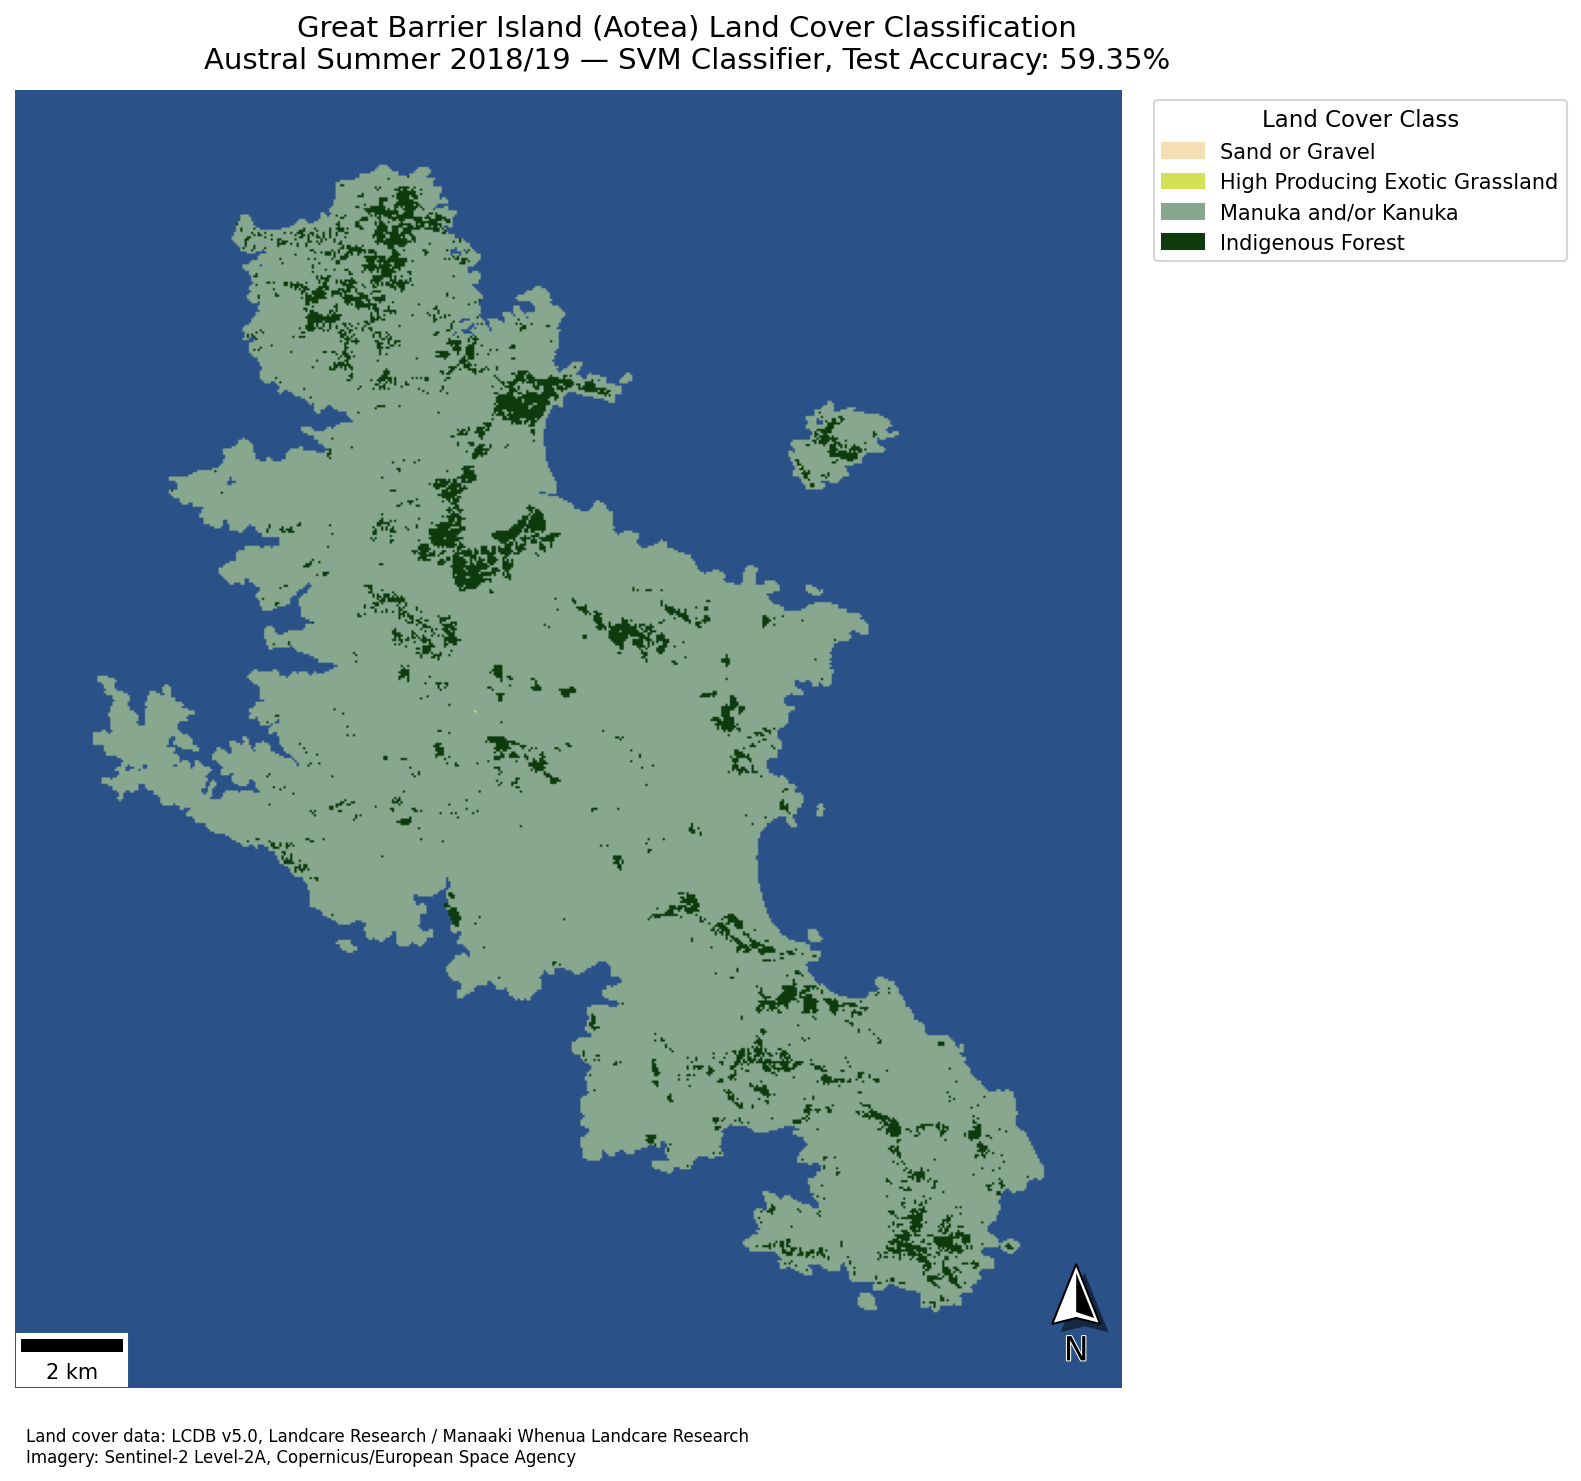

(600, 511, 4)


In [ ]:
sample_gbi = training_data_gbi.select(bands + ['lcdb_class']).sample(
    region=aoi_gbi,
    scale=10,
    numPixels=15000,   #<- increased from 5000
    seed=2,
    geometries=True
)

# 1. re-split train/test with the new larger sample
sample_gbi = sample_gbi.randomColumn('random', 2)
train_gbi = sample_gbi.filter(ee.Filter.lt('random', 0.8))
test_gbi = sample_gbi.filter(ee.Filter.gte('random', 0.8))

# 2. retrain the SVM on this new, bigger training set
svm_gbi = ee.Classifier.libsvm(kernelType='RBF', gamma=0.5, cost=10).train(
    features=train_gbi, classProperty='lcdb_class', inputProperties=bands
)

# 3. re-classify the WHOLE island image using this freshly retrained model
classified_gbi = s2_gbi.select(bands).classify(svm_gbi)

# 4. re-check test accuracy
tested_gbi = test_gbi.classify(svm_gbi, 'predicted')
y_true_gbi, y_pred_gbi = fc_to_lists(tested_gbi, 'lcdb_class', 'predicted')
svm_accuracy = accuracy_score(y_true_gbi, y_pred_gbi)
print(f"SVM Test Accuracy (numPixels=15000): {svm_accuracy:.2%}")

# 5. re-apply the remap (since this uses the freshly classified image)
classified_gbi_remapped = classified_gbi.remap(ee_from, ee_to)

# build the figure
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import urllib.request, tempfile
import matplotlib.image as mpimg
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib_map_utils import north_arrow
import math

land_mask = lcdb_image.mask()
classified_gbi_remapped = classified_gbi_remapped.updateMask(land_mask)

fig, ax = plt.subplots(figsize=(12, 10), dpi=150)
ax.set_facecolor('#4a90d9')

thumbnail_px = 600
thumb_url = classified_gbi_remapped.getThumbURL({
    'dimensions': thumbnail_px,
    'region': aoi_gbi,
    'format': 'png',
    'min': 1,
    'max': 13,
    'palette': palette_ordered
})

# legend
legend_elements = []
for code in remap_from:  # already sorted, matches palette_ordered order
    label = code_to_name[code]
    color = class_colors[code]
    legend_elements.append(mpatches.Patch(color=color, label=label))

ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1),
          fontsize=10, title="Land Cover Class", title_fontsize=11, frameon=True)

import numpy as np

with tempfile.NamedTemporaryFile(suffix=".png") as f:
    urllib.request.urlretrieve(thumb_url, f.name)
    img = mpimg.imread(f.name)

    # Masked/no-data pixels have alpha = 0 (fully transparent) — THIS is the real ocean indicator
    is_ocean = img[:, :, 3] == 0
    print("Number of ocean pixels detected:", is_ocean.sum())

    img_colored = img[:, :, :3].copy()
    ocean_blue = np.array([0.167, 0.320, 0.535])
    img_colored[is_ocean] = ocean_blue

    ax.imshow(img_colored)
    ax.axis('off')

# scale bar
def get_aoi_width_m(aoi):
    coords = aoi.bounds().coordinates().getInfo()[0]
    lons = [pt[0] for pt in coords]
    lats = [pt[1] for pt in coords]
    xmin, xmax = min(lons), max(lons)
    ymin, ymax = min(lats), max(lats)
    lat_mid = (ymin + ymax) / 2
    m_per_degree_lon = 111320 * math.cos(math.radians(lat_mid))
    return (xmax - xmin) * m_per_degree_lon

aoi_width_m = get_aoi_width_m(aoi_gbi)
dx = aoi_width_m / thumbnail_px
scalebar = ScaleBar(dx=dx, units="m", location="lower left", frameon=True)
ax.add_artist(scalebar)

# north arrow
north_arrow(ax=ax, location="lower right", scale=0.4, rotation={"degrees": 0})

# data attribution
ax.text(0.01, -0.03,
        "Land cover data: LCDB v5.0, Landcare Research / Manaaki Whenua Landcare Research\n"
        "Imagery: Sentinel-2 Level-2A, Copernicus/European Space Agency",
        transform=ax.transAxes, fontsize=8, va='top')

# title + performance stats on the figure itself
fig.suptitle(f"Great Barrier Island (Aotea) Land Cover Classification\n"
             f"Austral Summer 2018/19 — SVM Classifier, Test Accuracy: {svm_accuracy:.2%}",
             fontsize=14, y=0.98)

# Get the actual predicted classes (remapped codes) from your classification
class_histogram = classified_gbi_remapped.reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=aoi_gbi,
    scale=10,
    maxPixels=1e9
).getInfo()

# Extract just the remapped codes that were actually predicted (as integers, keys come back as strings)
predicted_remapped_codes = [int(k) for k in class_histogram['remapped'].keys()]

# Build a reverse lookup: remapped code -> original code (so we can find the right color/name)
remap_reverse = {v: k for k, v in remap_dict.items()}

# Build the legend using ONLY codes that were actually predicted
legend_elements = []
for remapped_code in sorted(predicted_remapped_codes):
    original_code = remap_reverse[remapped_code]
    label = code_to_name[original_code]
    color = class_colors[original_code]
    legend_elements.append(mpatches.Patch(color=color, label=label))

ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1),
          fontsize=10, title="Land Cover Class", title_fontsize=11, frameon=True)

plt.tight_layout()
plt.savefig('gbi_landcover.png', dpi=300, bbox_inches='tight')
plt.show()


print(img.shape)

In [ ]:
class_histogram = classified_gbi_remapped.reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=aoi_gbi,
    scale=10,
    maxPixels=1e9
).getInfo()

print(class_histogram)

{'remapped': {'10': 324849, '2': 8, '3': 621, '8': 3080650}}


In [ ]:
training_histogram = sample_gbi.reduceColumns(
    reducer=ee.Reducer.frequencyHistogram(),
    selectors=['lcdb_class']
).getInfo()

print(training_histogram)

{'histogram': {'1': 8, '10': 70, '40': 252, '41': 36, '45': 51, '46': 22, '51': 3, '52': 2246, '54': 561, '69': 926, '70': 12, '71': 10, '999': 35}}


In [ ]:
# check the "broadleaf indigenous hardwoods" as it is known to be grassland from ground truthing
check_point = ee.Geometry.Point([175.40746904055533,-36.15647576526814 ])  # your grassland coordinates

# What did the model predict here?
predicted_class = classified_gbi.reduceRegion(
    reducer=ee.Reducer.first(), geometry=check_point, scale=10
).getInfo()
print("Model predicted:", predicted_class)

# What are the actual Sentinel 2 band values here?
actual_values = s2_gbi.select(bands).reduceRegion(
    reducer=ee.Reducer.first(), geometry=check_point, scale=10
).getInfo()
print("Actual band values at this point:", actual_values)

# What does LCDB itself say this point should be?
lcdb_label = lcdb_image.reduceRegion(
    reducer=ee.Reducer.first(), geometry=check_point, scale=10
).getInfo()
print("LCDB ground truth label:", lcdb_label)